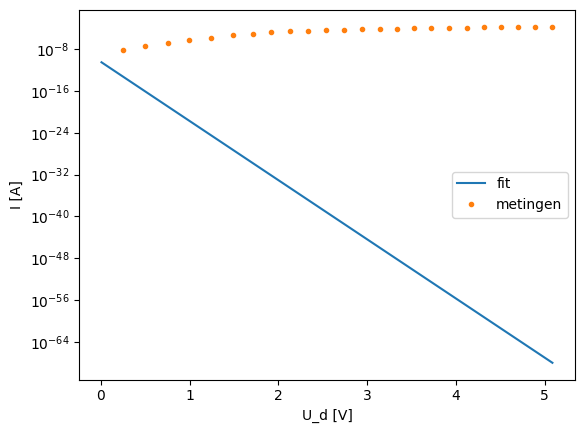

I_0 = 1.0000000001000001e-10 A
n = 1.5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

U_bs, U_R1, U_Bron = np.genfromtxt("meting spanning.csv", delimiter=";", skip_header=1, unpack=True)

R_1 = 4700  #De weerstand waar we de spanning er van hebben gemeten, in ohm

U_d = U_Bron - U_R1
I = U_R1 / R_1

q = -1.602176634e-19  # negatieve elementaire lading, C
k_B = 1.380649e-23   # J/K
T = 23.8 + 273.15    # kelvin

def diode(U_d, I_0, n):
    return I_0 * (np.exp(q * U_d / (n * k_B * T)-1))

params, cov = curve_fit(
    diode, U_d, I,
    p0=[1e-12, 1.5],
    bounds=([1e-20, 0.5], [1e-3, 5]),
    maxfev=20000
)

onz_UBron
onz_I
onz_Ud


x = np.linspace(min(U_d), max(U_d), 200)
y = diode(x, *params)

plt.semilogy(x, y, label="fit")
plt.semilogy(U_d, I, ".", label="metingen")
plt.xlabel("U_d [V]")
plt.ylabel("I [A]")
plt.legend()
plt.show()

print("I_0 =", params[0], "A")
print("n =", params[1])

